# Project 1, Part A: a ladder of classifiers

Train A1 to A6 on the same VOC training crops; select on validation; evaluate each final model once on test.
Loss for every model: 19-way softmax cross-entropy (`F.cross_entropy` on the raw scores); A1 and A2 add an L2 penalty on their weights.
Run **P1_0_Setup_and_Data** first. Use a GPU runtime (Runtime > Change runtime type > T4 GPU).

Save what later notebooks need to `CKPT_DIR` (`p1/checkpoints/` on your Drive): every model's weights, A2's feature statistics, and anything else you will reload.
Put your model classes and feature functions in `my_models.py` (the `%%writefile` cell below) so P1_V, P1_B and P1_665 can rebuild the models.

On Colab, start in a fresh session (Runtime > Disconnect and delete runtime in the previous notebook), and finish the Google Drive pop-up that the first cell opens.

Write your own training, evaluation, and visualization code (PyTorch, torchvision, OpenCV, scikit-learn, timm). A1 to A5 use no pretrained weights. AI tools may help you study; they may not write your code or report.

Library functions are listed in each step below, and in full in the handout's Appendix A.

In [1]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:                 # every notebook of the project shares one folder on your Google Drive
    from google.colab import drive
    try:                     # a sign-in pop-up opens: finish it within 10 minutes (Colab's default is 2)
        drive.mount('/content/drive', timeout_ms=600_000)
    except Exception as e:
        raise RuntimeError('Google Drive did not mount. Run this cell again and finish the sign-in pop-up, '
                           'with the same Google account in every notebook.') from e
ROOT = os.environ.get('P1_ROOT') or ('/content/drive/MyDrive/p1' if IN_COLAB else os.path.abspath('p1'))
os.environ['P1_ROOT'] = ROOT
os.makedirs(ROOT, exist_ok=True)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print('project folder:', ROOT)
assert os.path.exists(os.path.join(ROOT, 'p1_utils.py')), 'Run P1_0_Setup_and_Data.ipynb first: it writes p1_utils.py.'
from p1_utils import *
print_versions()

Mounted at /content/drive
project folder: /content/drive/MyDrive/p1
p1_utils: project folder /content/drive/MyDrive/p1 | OpenCV 4.14.0 | Colab: True
versions: python 3.13.16, torch 2.14.1+cu130, torchvision 0.29.1+cu130, timm 1.0.30, numpy 2.4.6, scikit-learn 1.6.1, pandas 2.2.3, matplotlib 3.10.0, pillow 11.3.0, pillow-heif 1.8.1, opencv 4.14.0, gpu Tesla T4


{'python': '3.13.16',
 'torch': '2.14.1+cu130',
 'torchvision': '0.29.1+cu130',
 'timm': '1.0.30',
 'numpy': '2.4.6',
 'scikit-learn': '1.6.1',
 'pandas': '2.2.3',
 'matplotlib': '3.10.0',
 'pillow': '11.3.0',
 'pillow-heif': '1.8.1',
 'opencv': '4.14.0',
 'gpu': 'Tesla T4'}

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
DEV = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', DEV)
MY_CLASSES = ['bicycle', 'bottle', 'chair', 'car', 'cat']     # TODO: your five classes (same in every notebook)

CKPT_DIR = "/content/drive/MyDrive/p1/checkpoints"

device: cuda


In [3]:
X64, y, img_id, is_test = load_crops(64)          # cached by P1_0
idx_train, idx_val, idx_test = make_splits(img_id, is_test)
HAS_PERSON = person_flags()                       # leave these crops out of every figure
print(len(idx_train), 'train,', len(idx_val), 'validation,', len(idx_test), 'test crops')

7541 train, 797 validation, 8381 test crops


In [4]:
train_ids = set(img_id[idx_train])
val_ids = set(img_id[idx_val])
test_ids = set(img_id[idx_test])

print("Train and Validation:", len(train_ids & val_ids))
print("Train and Test:", len(train_ids & test_ids))
print("Validation and Test:", len(val_ids & test_ids))

Train and Validation: 0
Train and Test: 0
Validation and Test: 0


In [5]:
%%writefile {ROOT}/my_models.py
# Your model classes (A3, A4, A5) and helpers that later notebooks need (e.g. A2 feature functions), and one
# preprocessing function per model (normalization constants included), so P1_V, P1_B and P1_665 prepare inputs
# exactly as P1_A did. Save the training statistics they need (e.g. channel means and stds) to CKPT_DIR.
# This cell writes the file; the next cell imports it. Re-run both after every change.
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import cv2
import timm


#A1
class A1Linear(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(3 * 32 * 32, 19)

        nn.init.zeros_(self.linear.weight)
        nn.init.zeros_(self.linear.bias)

    def forward(self, x):
        return self.linear(x.flatten(1))


def resize_a1(images):
    return np.stack([cv2.resize(i, (32, 32), interpolation=cv2.INTER_AREA) for i in images])


def preprocess_a1(images, mean, std):
    images = np.asarray(images)
    if images.shape[1:3] != (32, 32):
        images = resize_a1(images)

    x = images.astype(np.float32)
    mean = np.asarray(mean, dtype=np.float32).reshape(1, 1, 1, 3)
    std = np.asarray(std, dtype=np.float32).reshape(1, 1, 1, 3)
    x = (x - mean) / std

    return torch.from_numpy(x).permute(0, 3, 1, 2).contiguous()


#A2
class A2Linear(nn.Module):
  def __init__(self, feature_dim):
      super().__init__()
      self.linear = nn.Linear(feature_dim, 19)

      nn.init.zeros_(self.linear.weight)
      nn.init.zeros_(self.linear.bias)

  def forward(self, x):
      return self.linear(x)


def extract_a2_features(images):
    images = np.asarray(images)

    hog = cv2.HOGDescriptor(
        (64, 64), (16, 16), (8, 8), (8, 8), 9
    )

    kernels = []

    for theta in (0, np.pi / 4, np.pi / 2, 3 * np.pi / 4):
        for wavelength, size in ((4.0, 13), (8.0, 27)):
            kernel = cv2.getGaborKernel(
                ksize=(size, size),
                sigma=0.56 * wavelength,
                theta=theta,
                lambd=wavelength,
                gamma=0.5,
                psi=0.0,
                ktype=cv2.CV_32F,
            )

            kernel = kernel - kernel.mean()
            kernels.append(kernel)

    hsv_rows = []
    hog_rows = []
    gabor_rows = []

    for im in images:
        hsv = cv2.cvtColor(im, cv2.COLOR_RGB2HSV)
        gray = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)

        histograms = []

        for ch, upper in ((0, 180), (1, 256), (2, 256)):
            hist = cv2.calcHist(
                [hsv], [ch], None, [16], [0, upper]
            ).ravel()

            histograms.append(hist / hist.sum())

        hsv_rows.append(np.concatenate(histograms))
        hog_rows.append(hog.compute(gray).ravel())

        gray_float = gray.astype(np.float32) / 255.0
        gabor_features = []

        for kernel in kernels:
            response = cv2.filter2D(
                gray_float,
                cv2.CV_32F,
                kernel,
                borderType=cv2.BORDER_REFLECT_101,
            )

            absolute_response = np.abs(response)

            gabor_features.extend([
                absolute_response.mean(),
                absolute_response.var(),
            ])

        gabor_rows.append(gabor_features)

    return {
        "hsv": np.asarray(hsv_rows, dtype=np.float32),
        "hog": np.asarray(hog_rows, dtype=np.float32),
        "gabor": np.asarray(gabor_rows, dtype=np.float32),
    }


def standardize_a2(features, stats, feature_set):
    names = (
        ("hsv", "hog", "gabor")
        if feature_set == "concat"
        else (feature_set,)
    )

    blocks = [
        (features[name] - stats[f"{name}_mean"])
        / stats[f"{name}_std"]
        for name in names
    ]

    x = np.concatenate(blocks, axis=1).astype(np.float32)
    return torch.from_numpy(x)


def preprocess_a2(images, stats, feature_set):
    features = extract_a2_features(images)
    return standardize_a2(features, stats, feature_set)


# A3
class A3MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(3 * 32 * 32, 256)
        self.relu = nn.ReLU()
        self.output = nn.Linear(256, 19)

    def forward(self, x):
        x = x.flatten(1)
        x = self.hidden(x)
        x = self.relu(x)
        return self.output(x)


def resize_a3(images):
    return resize_a1(images)


def preprocess_a3(images, mean, std):
    return preprocess_a1(images, mean, std)



# A4
class A4BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3,
            stride=stride, padding=1, bias=False,
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3,
            stride=1, padding=1, bias=False,
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels, kernel_size=1,
                    stride=stride, bias=False,
                ),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class A4ResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem_conv = nn.Conv2d(
            3, 32, kernel_size=7, stride=1, padding=3, bias=False,
        )
        self.stem_bn = nn.BatchNorm2d(32)

        self.stage1 = nn.Sequential(
            A4BasicBlock(32, 32),
            A4BasicBlock(32, 32),
        )
        self.stage2 = nn.Sequential(
            A4BasicBlock(32, 64, stride=2),
            A4BasicBlock(64, 64),
        )
        self.stage3 = nn.Sequential(
            A4BasicBlock(64, 128, stride=2),
            A4BasicBlock(128, 128),
        )
        self.fc = nn.Linear(128, 19)

    def forward(self, x):
        x = F.relu(self.stem_bn(self.stem_conv(x)))
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = x.mean(dim=(2, 3))
        return self.fc(x)


def preprocess_a4(images, mean, std):
    x = np.asarray(images, dtype=np.float32)
    mean = np.asarray(mean, dtype=np.float32).reshape(1, 1, 1, 3)
    std = np.asarray(std, dtype=np.float32).reshape(1, 1, 1, 3)
    x = (x - mean) / std
    return torch.from_numpy(x).permute(0, 3, 1, 2).contiguous()


# A5
class A5ViT(nn.Module):
    def __init__(self):
        super().__init__()

        self.patch_embed = nn.Conv2d(
            3, 128, kernel_size=8, stride=8
        )

        self.cls_token = nn.Parameter(torch.zeros(1, 1, 128))
        self.pos_embed = nn.Parameter(torch.zeros(1, 65, 128))

        self.blocks = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=128,
                nhead=4,
                dim_feedforward=512,
                dropout=0.0,
                activation="gelu",
                batch_first=True,
                norm_first=True,
            )
            for _ in range(4)
        ])

        self.norm = nn.LayerNorm(128)
        self.head = nn.Linear(128, 19)

        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        x = self.patch_embed(x)
        x = x.flatten(2).transpose(1, 2)

        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat((cls, x), dim=1)
        x = x + self.pos_embed

        for block in self.blocks:
            x = block(x)

        cls = self.norm(x[:, 0])
        return self.head(cls)


def preprocess_a5(images, mean, std):
    return preprocess_a4(images, mean, std)


#A6
def A6ViT(pretrained=True):
    model = timm.create_model(
        "vit_tiny_patch16_224.augreg_in21k_ft_in1k",
        pretrained=pretrained,
    )

    torch.manual_seed(1)
    model.head = nn.Linear(192, 19)
    return model


def preprocess_a6(images, mean, std, device):
    x = torch.as_tensor(images, device=device)
    x = x.permute(0, 3, 1, 2).to(torch.float32).div_(255.0)

    if x.shape[-2:] != (224, 224):
        x = F.interpolate(
            x,
            size=(224, 224),
            mode="bilinear",
            align_corners=False,
        )

    mean = torch.as_tensor(mean, dtype=x.dtype, device=device).view(1, 3, 1, 1)
    std = torch.as_tensor(std, dtype=x.dtype, device=device).view(1, 3, 1, 1)
    return (x - mean) / std

Overwriting /content/drive/MyDrive/p1/my_models.py


In [6]:
import importlib, my_models
importlib.reload(my_models)
from my_models import *

In [7]:
TABLE1 = []      # one dict per row: model, mean per-class test acc (19 classes), acc on each of MY_CLASSES,
                 # input size, parameters (or feature dimension), training data, training time, hardware

In [8]:
# TODO Mean per-class accuracy over a given set of classes (handout, Metrics).
# Predictions always use all 19 classes, also when you evaluate on your five.

def mean_per_class_accuracy(y_true, predictions, classes=range(19)):
    def to_numpy(x):
        if isinstance(x, torch.Tensor):
            return x.detach().cpu().numpy()
        return np.asarray(x)

    y_true = to_numpy(y_true)
    predictions = to_numpy(predictions)

    if predictions.ndim == 2:
        predictions = predictions.argmax(axis=1)

    classes = list(classes)
    per_class = {}

    for c in classes:
        mask = (y_true == c)
        per_class[c] = float((predictions[mask] == c).mean())

    mean_acc = float(np.mean(list(per_class.values())))
    return mean_acc, per_class

## The training loop, shared by A1 to A6

Algorithm 3 in the handout's Appendix A. Functions:
`torch.from_numpy(x).permute(0, 3, 1, 2).float().to(DEV)` (a batch of images to the GPU, channels first);
`F.cross_entropy(logits, y)`; `torch.optim.AdamW(...)` or `torch.optim.Adam(...)`;
`opt.zero_grad()`, `loss.backward()`, `opt.step()`; `model.train()`, `model.eval()`, `torch.no_grad()`, `logits.argmax(1)`;
`torch.save(model.state_dict(), path)`; `torch.manual_seed(0)`, `np.random.default_rng(0).permutation(n)`.

In [9]:
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F


@torch.no_grad()
def evaluate_model(model, X, labels, indices, batch_size=256):
    model.eval()
    indices = np.asarray(indices, dtype=np.int64)
    predictions = []

    for start in range(0, len(indices), batch_size):
        ids = torch.from_numpy(indices[start:start + batch_size])

        xb = X[ids].to(DEV)
        logits = model(xb)
        predictions.append(logits.argmax(1).cpu().numpy())

    predictions = np.concatenate(predictions)
    targets = labels[torch.from_numpy(indices)].numpy()

    return mean_per_class_accuracy(
        targets, predictions, classes=range(19)
    )


def train_model(
    model, X, labels, train_indices, val_indices,
    *,
    epochs=60,
    batch_size=256,
    lr=1e-3,
    l2=0.0,
    penalty_parameters=None,
    optimizer_cls=torch.optim.Adam,
    seed=0,
):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    model = model.to(DEV)
    train_indices = np.asarray(train_indices, dtype=np.int64)

    opt = optimizer_cls(model.parameters(), lr=lr, weight_decay=0.0)

    best_score = -float("inf")
    best_state = None
    best_epoch = 0

    if str(DEV).startswith("cuda"):
        torch.cuda.synchronize()
    start_time = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        order = train_indices[rng.permutation(len(train_indices))]
        total_loss = 0.0

        for start in range(0, len(order), batch_size):
            ids = torch.from_numpy(order[start:start + batch_size])

            xb = X[ids].to(DEV)
            yb = labels[ids].to(DEV)

            opt.zero_grad()
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)

            if l2 != 0:
                penalty = sum(
                    p.square().sum()
                    for p in penalty_parameters(model)
                )
                loss = loss + l2 * penalty

            loss.backward()
            opt.step()

            total_loss += loss.item() * len(ids)

        val_score, _ = evaluate_model(
            model, X, labels, val_indices, batch_size
        )

        if val_score > best_score:
            best_score = val_score
            best_epoch = epoch
            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Epoch {epoch:02d}/{epochs} | "
                f"Loss {total_loss / len(train_indices):.4f} | "
                f"Val mean-class acc {val_score:.2%}"
            )

    if str(DEV).startswith("cuda"):
        torch.cuda.synchronize()
    training_seconds = time.perf_counter() - start_time

    model.load_state_dict(best_state)
    model.eval()

    print(
        f"Best epoch: {best_epoch} | "
        f"Best validation: {best_score:.2%}"
    )

    return model, training_seconds

## A1: linear classifier on 32x32 pixels

In [10]:
# TODO A1: 19-way linear softmax classifier on 32x32 RGB pixels.
# Resize the 64 px crops yourself; standardize each color channel with TRAINING statistics; start from zero weights.
# Settings: Adam, lr 1e-3, batch 256, 60 epochs, L2 penalty (weights only, not the bias) from {1e-2, 1, 10}, best validation epoch.
# A1 is the model at L2 = 1 (readable class templates); report it in Table 1. Also train 1e-2 and 10, and save all three for V1.
# Functions: cv2.resize(im, (32, 32), interpolation=cv2.INTER_AREA);
#    X.reshape(-1, 3).mean(axis=0) and .std(axis=0) (per channel); nn.Linear(3072, 19);
#    nn.init.zeros_(model.weight); nn.init.zeros_(model.bias); (model.weight ** 2).sum()

ckpt_dir = Path(CKPT_DIR)
ckpt_dir.mkdir(parents=True, exist_ok=True)

X32 = resize_a1(X64)


train_pixels = X32[idx_train].reshape(-1, 3)

a1_mean = train_pixels.mean(
    axis=0, dtype=np.float64
).astype(np.float32)

a1_std = train_pixels.std(
    axis=0, dtype=np.float64
).astype(np.float32)

a1_std = np.where(a1_std > 0, a1_std, 1.0).astype(np.float32)
del train_pixels


np.savez(
    ckpt_dir / "a1_stats.npz",
    mean=a1_mean,
    std=a1_std,
)


X_a1 = preprocess_a1(X32, a1_mean, a1_std)
labels = torch.as_tensor(np.asarray(y), dtype=torch.long)

hardware = (
    torch.cuda.get_device_name(0)
    if str(DEV).startswith("cuda")
    else str(DEV)
)

A1_MODELS = {}
A1_TIMES = {}

a1_settings = [
    (0.01, "0.01"),
    (1.0, "1"),
    (10.0, "10"),
]

for l2, tag in a1_settings:
    print(f"\nTraining A1: L2 = {l2}")

    torch.manual_seed(0)
    model = A1Linear()

    model, training_seconds = train_model(
        model,
        X_a1,
        labels,
        idx_train,
        idx_val,
        epochs=60,
        batch_size=256,
        lr=1e-3,
        l2=l2,
        penalty_parameters=lambda m: [m.linear.weight],
        optimizer_cls=torch.optim.Adam,
        seed=0,
    )

    torch.save(
        {
            name: value.detach().cpu()
            for name, value in model.state_dict().items()
        },
        ckpt_dir / f"a1_l2_{tag}.pt",
    )

    A1_MODELS[l2] = model
    A1_TIMES[l2] = training_seconds


A1_TEST = {}

for l2, tag in a1_settings:
    mean_acc, per_class = evaluate_model(
        A1_MODELS[l2],
        X_a1,
        labels,
        idx_test,
    )

    A1_TEST[l2] = (mean_acc, per_class)

    np.savez(
        ckpt_dir / f"a1_l2_{tag}_test.npz",
        mean_per_class_acc=mean_acc,
        per_class_acc=np.array([per_class[c] for c in range(19)]),
        training_seconds=A1_TIMES[l2],
        hardware=hardware,
    )

    print(
        f"L2 = {l2:g} | "
        f"Test mean-class accuracy: {mean_acc:.2%}"
    )

a1_model = A1_MODELS[1.0]
a1_mean_acc, a1_per_class = A1_TEST[1.0]

a1_row = {
    "model": "A1",
    "mean_per_class_test_acc": a1_mean_acc,
    "per_class_test_acc": a1_per_class,
    "input_size": "32×32 RGB",
    "parameters": sum(p.numel() for p in a1_model.parameters()),
    "training_data": f"VOC train: {len(idx_train)} crops",
    "training_time_seconds": A1_TIMES[1.0],
    "hardware": hardware,
}

TABLE1[:] = [row for row in TABLE1 if row["model"] != "A1"]
TABLE1.append(a1_row)


Training A1: L2 = 0.01
Epoch 01/60 | Loss 2.8282 | Val mean-class acc 20.13%
Epoch 10/60 | Loss 2.1628 | Val mean-class acc 21.33%
Epoch 20/60 | Loss 2.0665 | Val mean-class acc 22.32%
Epoch 30/60 | Loss 2.0283 | Val mean-class acc 22.88%
Epoch 40/60 | Loss 2.0031 | Val mean-class acc 19.98%
Epoch 50/60 | Loss 1.9928 | Val mean-class acc 20.05%
Epoch 60/60 | Loss 1.9823 | Val mean-class acc 22.21%
Best epoch: 39 | Best validation: 23.77%

Training A1: L2 = 1.0
Epoch 01/60 | Loss 2.9703 | Val mean-class acc 17.89%
Epoch 10/60 | Loss 2.7996 | Val mean-class acc 18.19%
Epoch 20/60 | Loss 2.7842 | Val mean-class acc 16.71%
Epoch 30/60 | Loss 2.7801 | Val mean-class acc 16.42%
Epoch 40/60 | Loss 2.7636 | Val mean-class acc 15.42%
Epoch 50/60 | Loss 2.7655 | Val mean-class acc 16.62%
Epoch 60/60 | Loss 2.7610 | Val mean-class acc 16.08%
Best epoch: 41 | Best validation: 18.65%

Training A1: L2 = 10.0
Epoch 01/60 | Loss 3.0988 | Val mean-class acc 10.49%
Epoch 10/60 | Loss 2.9455 | Val mean-

## A2: hand-crafted features + the same linear classifier

In [11]:
# TODO A2: on 64x64 crops, with OpenCV: an HSV color histogram, HOG (cv2.HOGDescriptor), Gabor response statistics,
# and their concatenation (four rows of Table 1). Suggested settings are in the handout. Standardize each feature block with
# training statistics before concatenating. Same classifier settings as A1, with L2 from {1e-5, 1e-3} for each feature set.
# Save the statistics and classifier for Part B.
# Functions: cv2.cvtColor(im, cv2.COLOR_RGB2GRAY); cv2.cvtColor(im, cv2.COLOR_RGB2HSV);
#    cv2.calcHist([hsv], [ch], None, [16], [0, 180]) (hue; [0, 256] for S and V);
#    cv2.HOGDescriptor((64, 64), (16, 16), (8, 8), (8, 8), 9).compute(gray);
#    cv2.getGaborKernel(ksize, sigma, theta, lambd, gamma, psi); cv2.filter2D(gray, cv2.CV_32F, kernel);
#    feats.mean(axis=0) and feats.std(axis=0) (per feature, training rows)
from pathlib import Path

ckpt_dir = Path(CKPT_DIR)
ckpt_dir.mkdir(parents=True, exist_ok=True)

labels = torch.as_tensor(np.asarray(y), dtype=torch.long)

a2_features = extract_a2_features(X64)
a2_stats = {}

for name in ("hsv", "hog", "gabor"):
    train_features = a2_features[name][idx_train]

    mean = train_features.mean(
        axis=0, dtype=np.float64
    ).astype(np.float32)

    std = train_features.std(
        axis=0, dtype=np.float64
    ).astype(np.float32)

    std = np.where(std > 0, std, 1.0).astype(np.float32)

    a2_stats[f"{name}_mean"] = mean
    a2_stats[f"{name}_std"] = std

np.savez(ckpt_dir / "a2_stats.npz", **a2_stats)

A2_INPUTS = {
    name: standardize_a2(a2_features, a2_stats, name)
    for name in ("hsv", "hog", "gabor", "concat")
}

for name, features in A2_INPUTS.items():
    print(f"{name}: {features.shape[1]} features")

hardware = (
    torch.cuda.get_device_name(0)
    if str(DEV).startswith("cuda")
    else str(DEV)
)

A2_MODELS = {}
A2_TIMES = {}
A2_L2 = {}

for name, X_features in A2_INPUTS.items():
    best_val = -float("inf")

    for l2 in (1e-5, 1e-3):
        print(f"\nTraining A2-{name}: L2 = {l2}")

        torch.manual_seed(0)
        model = A2Linear(X_features.shape[1])

        model, training_seconds = train_model(
            model,
            X_features,
            labels,
            idx_train,
            idx_val,
            epochs=60,
            batch_size=256,
            lr=1e-3,
            l2=l2,
            penalty_parameters=lambda m: [m.linear.weight],
            optimizer_cls=torch.optim.Adam,
            seed=0,
        )

        val_acc, _ = evaluate_model(
            model, X_features, labels, idx_val
        )

        if val_acc > best_val:
            best_val = val_acc
            A2_MODELS[name] = model
            A2_TIMES[name] = training_seconds
            A2_L2[name] = l2

    torch.save(
        {
            key: value.detach().cpu()
            for key, value in A2_MODELS[name].state_dict().items()
        },
        ckpt_dir / f"a2_{name}.pt",
    )

    print(
        f"Selected A2-{name} | "
        f"L2={A2_L2[name]:g} | "
        f"Validation={best_val:.2%}"
    )

np.savez(ckpt_dir / "a2_selected_l2.npz", **A2_L2)


A2_TEST = {}

for name, model in A2_MODELS.items():
    mean_acc, per_class = evaluate_model(
        model,
        A2_INPUTS[name],
        labels,
        idx_test,
    )

    A2_TEST[name] = (mean_acc, per_class)

    np.savez(
        ckpt_dir / f"a2_{name}_test.npz",
        mean_per_class_acc=mean_acc,
        per_class_acc=np.array([
            per_class[c] for c in range(19)
        ]),
        selected_l2=A2_L2[name],
        training_seconds=A2_TIMES[name],
        hardware=hardware,
    )

    model_name = f"A2-{name}"

    row = {
        "model": model_name,
        "mean_per_class_test_acc": mean_acc,
        "per_class_test_acc": per_class,
        "input_size": "64×64 RGB",
        "feature_dimension": A2_INPUTS[name].shape[1],
        "parameters": sum(p.numel() for p in model.parameters()),
        "training_data": f"VOC train: {len(idx_train)} crops",
        "training_time_seconds": A2_TIMES[name],
        "hardware": hardware,
        "l2": A2_L2[name],
    }

    TABLE1[:] = [
        existing for existing in TABLE1
        if existing["model"] != model_name
    ]
    TABLE1.append(row)

    print(
        f"{model_name} | "
        f"L2={A2_L2[name]:g} | "
        f"Test mean-class accuracy={mean_acc:.2%}"
    )

hsv: 48 features
hog: 1764 features
gabor: 16 features
concat: 1828 features

Training A2-hsv: L2 = 1e-05
Epoch 01/60 | Loss 2.8868 | Val mean-class acc 14.39%
Epoch 10/60 | Loss 2.5700 | Val mean-class acc 15.16%
Epoch 20/60 | Loss 2.5139 | Val mean-class acc 15.61%
Epoch 30/60 | Loss 2.4945 | Val mean-class acc 15.43%
Epoch 40/60 | Loss 2.4855 | Val mean-class acc 15.21%
Epoch 50/60 | Loss 2.4812 | Val mean-class acc 15.17%
Epoch 60/60 | Loss 2.4790 | Val mean-class acc 14.79%
Best epoch: 21 | Best validation: 15.79%

Training A2-hsv: L2 = 0.001
Epoch 01/60 | Loss 2.8868 | Val mean-class acc 14.39%
Epoch 10/60 | Loss 2.5748 | Val mean-class acc 15.16%
Epoch 20/60 | Loss 2.5221 | Val mean-class acc 15.59%
Epoch 30/60 | Loss 2.5048 | Val mean-class acc 15.43%
Epoch 40/60 | Loss 2.4971 | Val mean-class acc 15.28%
Epoch 50/60 | Loss 2.4938 | Val mean-class acc 15.17%
Epoch 60/60 | Loss 2.4923 | Val mean-class acc 15.13%
Best epoch: 21 | Best validation: 16.00%
Selected A2-hsv | L2=0.001 

## A3: MLP on pixels

In [12]:
# TODO A3: 32x32 RGB input, one hidden layer of 256 units, ReLU, 19 outputs. Suggested: AdamW, batch 64, 30 epochs,
# lr 1e-3, weight decay 1e-4. Record training loss and validation accuracy per epoch for the curves.
# Functions: nn.Module; nn.Sequential; nn.Linear; nn.ReLU; x.flatten(1)
from time import perf_counter


ckpt_dir = Path(CKPT_DIR)
ckpt_dir.mkdir(parents=True, exist_ok=True)

with np.load(ckpt_dir / "a1_stats.npz") as stats:
    X_a3 = preprocess_a3(X64, stats["mean"], stats["std"])

assert X_a3.dtype == torch.float32
assert X_a3.shape == (len(X64), 3, 32, 32)

labels = torch.as_tensor(np.asarray(y), dtype=torch.long)
train_indices = np.asarray(idx_train)

if train_indices.dtype == np.bool_:
    train_indices = np.flatnonzero(train_indices)

torch.manual_seed(0)
rng = np.random.default_rng(0)

A3_MODEL = A3MLP().to(DEV)
optimizer = torch.optim.AdamW(
    A3_MODEL.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

epochs = 30
batch_size = 64
train_losses = []
val_accuracies = []
best_val = -float("inf")
best_epoch = 0
best_state = None

hardware = (
    torch.cuda.get_device_name(DEV)
    if torch.device(DEV).type == "cuda"
    else str(DEV)
)

start_time = perf_counter()

for epoch in range(1, epochs + 1):
    A3_MODEL.train()
    shuffled_indices = rng.permutation(train_indices)
    total_loss = 0.0

    for start in range(0, len(shuffled_indices), batch_size):
        batch_idx = shuffled_indices[start:start + batch_size]
        xb = X_a3[batch_idx].to(DEV)
        yb = labels[batch_idx].to(DEV)

        optimizer.zero_grad()
        logits = A3_MODEL(xb)
        loss = F.cross_entropy(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_idx)

    train_loss = total_loss / len(train_indices)

    A3_MODEL.eval()
    with torch.no_grad():
        val_acc, _ = evaluate_model(A3_MODEL, X_a3, labels, idx_val)
    val_acc = float(val_acc)

    train_losses.append(train_loss)
    val_accuracies.append(val_acc)

    if val_acc > best_val:
        best_val = val_acc
        best_epoch = epoch
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in A3_MODEL.state_dict().items()
        }

    print(
        f"A3 | Epoch {epoch:02d}/{epochs} | "
        f"Train loss={train_loss:.4f} | "
        f"Validation={val_acc:.2%}"
    )

A3_TIME = perf_counter() - start_time

A3_MODEL.load_state_dict(best_state)
torch.save(best_state, ckpt_dir / "a3.pt")

np.savez(
    ckpt_dir / "a3_history.npz",
    epoch=np.arange(1, epochs + 1),
    train_loss=np.asarray(train_losses),
    val_mean_per_class_acc=np.asarray(val_accuracies),
    best_epoch=best_epoch,
)

A3_MODEL.eval()
with torch.no_grad():
    mean_acc, per_class = evaluate_model(A3_MODEL, X_a3, labels, idx_test)

A3_TEST = (mean_acc, per_class)

np.savez(
    ckpt_dir / "a3_test.npz",
    mean_per_class_acc=mean_acc,
    per_class_acc=np.array([per_class[c] for c in range(19)]),
    best_epoch=best_epoch,
    training_seconds=A3_TIME,
    hardware=hardware,
)

row = {
    "model": "A3",
    "mean_per_class_test_acc": mean_acc,
    "per_class_test_acc": per_class,
    "input_size": "32×32 RGB",
    "feature_dimension": 32 * 32 * 3,
    "parameters": sum(p.numel() for p in A3_MODEL.parameters()),
    "training_data": f"VOC train: {len(train_indices)} crops",
    "training_time_seconds": A3_TIME,
    "hardware": hardware,
    "weight_decay": 1e-4,
}

TABLE1[:] = [existing for existing in TABLE1 if existing["model"] != "A3"]
TABLE1.append(row)

print(
    f"Selected A3 | Best epoch={best_epoch} | "
    f"Validation={best_val:.2%} | "
    f"Test mean-class accuracy={mean_acc:.2%}"
)

A3 | Epoch 01/30 | Train loss=2.7260 | Validation=18.99%
A3 | Epoch 02/30 | Train loss=2.2559 | Validation=24.23%
A3 | Epoch 03/30 | Train loss=1.9968 | Validation=24.76%
A3 | Epoch 04/30 | Train loss=1.8066 | Validation=23.76%
A3 | Epoch 05/30 | Train loss=1.6259 | Validation=26.09%
A3 | Epoch 06/30 | Train loss=1.4121 | Validation=23.32%
A3 | Epoch 07/30 | Train loss=1.2698 | Validation=24.05%
A3 | Epoch 08/30 | Train loss=1.1287 | Validation=26.48%
A3 | Epoch 09/30 | Train loss=0.9849 | Validation=26.43%
A3 | Epoch 10/30 | Train loss=0.8808 | Validation=25.22%
A3 | Epoch 11/30 | Train loss=0.7940 | Validation=24.69%
A3 | Epoch 12/30 | Train loss=0.6598 | Validation=24.71%
A3 | Epoch 13/30 | Train loss=0.5630 | Validation=25.88%
A3 | Epoch 14/30 | Train loss=0.4822 | Validation=25.08%
A3 | Epoch 15/30 | Train loss=0.4423 | Validation=24.14%
A3 | Epoch 16/30 | Train loss=0.4633 | Validation=23.93%
A3 | Epoch 17/30 | Train loss=0.4043 | Validation=25.03%
A3 | Epoch 18/30 | Train loss=0

## A4: CNN from scratch

Write your milestone predictions for A4, A5, A6-H, and A6-L **before** you train any of them. Then run the overfit check before the full A4 run.

In [13]:
# TODO Overfit check: a fresh A4, 150 updates on one batch of 64 training crops, no flips, AdamW lr 1e-3. Accuracy on
# those same 64 crops should exceed 0.9; if it does not, look for a bug in the data, the model, or the loop first.
from my_models import A4ResNet, preprocess_a4

ckpt_dir = Path(CKPT_DIR)
ckpt_dir.mkdir(parents=True, exist_ok=True)

labels = torch.as_tensor(np.asarray(y), dtype=torch.long)
train_indices = np.asarray(idx_train)
if train_indices.dtype == np.bool_:
    train_indices = np.flatnonzero(train_indices)

train_rgb = np.asarray(X64)[train_indices]
a4_mean = train_rgb.mean(axis=(0, 1, 2), dtype=np.float64).astype(np.float32)
a4_std = train_rgb.std(axis=(0, 1, 2), dtype=np.float64).astype(np.float32)
a4_std = np.where(a4_std > 0, a4_std, 1.0).astype(np.float32)
del train_rgb

np.savez(ckpt_dir / "a4_stats.npz", mean=a4_mean, std=a4_std)
X_a4 = preprocess_a4(X64, a4_mean, a4_std)

torch.manual_seed(0)
check_rng = np.random.default_rng(0)
check_idx = check_rng.choice(train_indices, size=64, replace=False)
check_x = X_a4[check_idx].to(DEV)
check_y = labels[check_idx].to(DEV)

check_model = A4ResNet().to(DEV)
check_optimizer = torch.optim.AdamW(
    check_model.parameters(), lr=1e-3, weight_decay=1e-4,
)

check_model.train()
for step in range(150):
    check_optimizer.zero_grad()
    logits = check_model(check_x)
    loss = F.cross_entropy(logits, check_y)
    loss.backward()
    check_optimizer.step()

check_model.eval()
with torch.no_grad():
    predictions = check_model(check_x).argmax(dim=1)
    check_correct = (predictions == check_y).sum().item()

A4_OVERFIT_ACC = check_correct / len(check_y)
print(f"A4 overfit check | {check_correct}/64 | Accuracy={A4_OVERFIT_ACC:.2%}")

assert A4_OVERFIT_ACC > 0.90, (
    "A4 overfit check failed. Check the image-label alignment, "
    "residual blocks, and parameter updates before full training."
)

A4 overfit check | 64/64 | Accuracy=100.00%


In [14]:
# TODO A4: 64x64 input; required (report any change), a small ResNet: stem = 7x7 conv (32 channels, stride 1, padding 3), BN, ReLU;
# three residual stages of widths 32, 64, 128, two basic blocks each; global average pooling; linear output.
# Basic block: 3x3 conv (padding 1), BN, ReLU, 3x3 conv (padding 1), BN; add the shortcut; then ReLU. The first block of
# stages 2 and 3 uses stride 2 in its first conv and a projection shortcut (1x1 conv with stride 2, then BN); all other strides
# are 1 and all other shortcuts the identity.
# Horizontal flips (p = 0.5), nothing else. Keep the checkpoint with the best validation accuracy.
# Before training, save a copy of the initial weights (copy.deepcopy(model.state_dict())) to CKPT_DIR: V4(a) needs them.
# Functions: nn.Conv2d(cin, cout, k, stride, padding, bias=False); nn.BatchNorm2d; F.relu; x.mean(dim=(2, 3));
#    torch.rand; torch.where; x.flip(3); copy.deepcopy(model.state_dict())
import copy
from time import perf_counter

torch.manual_seed(0)
rng = np.random.default_rng(0)

A4_MODEL = A4ResNet()
torch.save(
    copy.deepcopy(A4_MODEL.state_dict()),
    ckpt_dir / "a4_initial.pt",
)
A4_MODEL = A4_MODEL.to(DEV)

optimizer = torch.optim.AdamW(
    A4_MODEL.parameters(), lr=1e-3, weight_decay=1e-4,
)

epochs = 30
batch_size = 64
train_losses = []
val_accuracies = []
best_val = -float("inf")
best_epoch = 0
best_state = None

hardware = (
    torch.cuda.get_device_name(DEV)
    if torch.device(DEV).type == "cuda"
    else str(DEV)
)

start_time = perf_counter()

for epoch in range(1, epochs + 1):
    A4_MODEL.train()
    shuffled_indices = rng.permutation(train_indices)
    total_loss = 0.0

    for start in range(0, len(shuffled_indices), batch_size):
        batch_idx = shuffled_indices[start:start + batch_size]
        xb = X_a4[batch_idx].to(DEV)
        yb = labels[batch_idx].to(DEV)

        flip_mask = torch.rand(len(xb), 1, 1, 1, device=xb.device) < 0.5
        xb = torch.where(flip_mask, xb.flip(3), xb)

        optimizer.zero_grad()
        logits = A4_MODEL(xb)
        loss = F.cross_entropy(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_idx)

    train_loss = total_loss / len(train_indices)

    A4_MODEL.eval()
    with torch.no_grad():
        val_acc, _ = evaluate_model(A4_MODEL, X_a4, labels, idx_val)
    val_acc = float(val_acc)

    train_losses.append(train_loss)
    val_accuracies.append(val_acc)

    if val_acc > best_val:
        best_val = val_acc
        best_epoch = epoch
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in A4_MODEL.state_dict().items()
        }

    print(
        f"A4 | Epoch {epoch:02d}/{epochs} | "
        f"Train loss={train_loss:.4f} | Validation={val_acc:.2%}"
    )

A4_TIME = perf_counter() - start_time

A4_MODEL.load_state_dict(best_state)
torch.save(best_state, ckpt_dir / "a4.pt")

np.savez(
    ckpt_dir / "a4_history.npz",
    epoch=np.arange(1, epochs + 1),
    train_loss=np.asarray(train_losses),
    val_mean_per_class_acc=np.asarray(val_accuracies),
    best_epoch=best_epoch,
    overfit_check_acc=A4_OVERFIT_ACC,
)

A4_MODEL.eval()
with torch.no_grad():
    mean_acc, per_class = evaluate_model(A4_MODEL, X_a4, labels, idx_test)

A4_TEST = (mean_acc, per_class)

np.savez(
    ckpt_dir / "a4_test.npz",
    mean_per_class_acc=mean_acc,
    per_class_acc=np.array([per_class[c] for c in range(19)]),
    best_epoch=best_epoch,
    training_seconds=A4_TIME,
    hardware=hardware,
)

row = {
    "model": "A4",
    "mean_per_class_test_acc": mean_acc,
    "per_class_test_acc": per_class,
    "input_size": "64×64 RGB",
    "parameters": sum(p.numel() for p in A4_MODEL.parameters()),
    "training_data": f"VOC train: {len(train_indices)} crops",
    "training_time_seconds": A4_TIME,
    "hardware": hardware,
    "weight_decay": 1e-4,
}

TABLE1[:] = [existing for existing in TABLE1 if existing["model"] != "A4"]
TABLE1.append(row)

print(
    f"Selected A4 | Best epoch={best_epoch} | "
    f"Validation={best_val:.2%} | Test mean-class accuracy={mean_acc:.2%}"
)

A4 | Epoch 01/30 | Train loss=2.5036 | Validation=18.11%
A4 | Epoch 02/30 | Train loss=2.3097 | Validation=19.47%
A4 | Epoch 03/30 | Train loss=2.1715 | Validation=25.38%
A4 | Epoch 04/30 | Train loss=2.0145 | Validation=29.23%
A4 | Epoch 05/30 | Train loss=1.8958 | Validation=33.04%
A4 | Epoch 06/30 | Train loss=1.8005 | Validation=34.44%
A4 | Epoch 07/30 | Train loss=1.7052 | Validation=42.42%
A4 | Epoch 08/30 | Train loss=1.6175 | Validation=37.59%
A4 | Epoch 09/30 | Train loss=1.5333 | Validation=44.26%
A4 | Epoch 10/30 | Train loss=1.4563 | Validation=41.70%
A4 | Epoch 11/30 | Train loss=1.4007 | Validation=46.79%
A4 | Epoch 12/30 | Train loss=1.3160 | Validation=53.57%
A4 | Epoch 13/30 | Train loss=1.2577 | Validation=42.15%
A4 | Epoch 14/30 | Train loss=1.2091 | Validation=51.88%
A4 | Epoch 15/30 | Train loss=1.1324 | Validation=48.07%
A4 | Epoch 16/30 | Train loss=1.0914 | Validation=50.03%
A4 | Epoch 17/30 | Train loss=1.0417 | Validation=52.61%
A4 | Epoch 18/30 | Train loss=0

## A5: ViT from scratch

In [15]:
# TODO A5: 64x64 input; required (report any change): 8x8 patches embedded by an 8x8 conv with stride 8 (64 tokens of
# width 128), a learned class token, learned position embeddings, 4 pre-norm blocks (4 heads, MLP ratio 4 = hidden width 512,
# GELU, no dropout), a final
# LayerNorm, and a linear output on the class token. With nn.TransformerEncoderLayer set norm_first=True, activation='gelu',
# dropout=0.0, batch_first=True: its defaults differ. Same input and augmentation as A4; lr 3e-4, weight decay 1e-2.
# Report the parameter counts of A4 and A5.
# Functions: nn.Conv2d(3, 128, 8, 8); nn.Parameter(torch.zeros(1, 1, 128));
#    nn.TransformerEncoderLayer(128, 4, 512, dropout=0.0, activation='gelu', batch_first=True, norm_first=True);
#    nn.TransformerEncoder(layer, 4, enable_nested_tensor=False); nn.LayerNorm(128); torch.cat
from my_models import A4ResNet, A5ViT

def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


a4_params = count_trainable_parameters(A4ResNet())

torch.manual_seed(0)
rng = np.random.default_rng(0)

A5_MODEL = A5ViT().to(DEV)
a5_params = count_trainable_parameters(A5_MODEL)

print(f"A4 parameters: {a4_params:,}")
print(f"A5 parameters: {a5_params:,}")

optimizer = torch.optim.AdamW(
    A5_MODEL.parameters(),
    lr=3e-4,
    weight_decay=1e-2,
)

epochs = 30
batch_size = 64
train_losses = []
val_accuracies = []
best_val = -float("inf")
best_epoch = 0
best_state = None

start_time = perf_counter()

for epoch in range(1, epochs + 1):
    A5_MODEL.train()
    shuffled_indices = rng.permutation(train_indices)
    total_loss = 0.0

    for start in range(0, len(shuffled_indices), batch_size):
        batch_idx = shuffled_indices[start:start + batch_size]
        xb = X_a4[batch_idx].to(DEV)
        yb = labels[batch_idx].to(DEV)

        flip_mask = torch.rand(len(xb), 1, 1, 1, device=xb.device) < 0.5
        xb = torch.where(flip_mask, xb.flip(3), xb)

        optimizer.zero_grad()
        logits = A5_MODEL(xb)
        loss = F.cross_entropy(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_idx)

    train_loss = total_loss / len(train_indices)

    A5_MODEL.eval()
    with torch.no_grad():
        val_acc, _ = evaluate_model(A5_MODEL, X_a4, labels, idx_val)

    val_acc = float(val_acc)
    train_losses.append(train_loss)
    val_accuracies.append(val_acc)

    if val_acc > best_val:
        best_val = val_acc
        best_epoch = epoch
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in A5_MODEL.state_dict().items()
        }

    print(
        f"A5 | Epoch {epoch:02d}/{epochs} | "
        f"Train loss={train_loss:.4f} | Validation={val_acc:.2%}"
    )

A5_TIME = perf_counter() - start_time

A5_MODEL.load_state_dict(best_state)
torch.save(best_state, ckpt_dir / "a5.pt")

np.savez(
    ckpt_dir / "a5_history.npz",
    epoch=np.arange(1, epochs + 1),
    train_loss=np.asarray(train_losses),
    val_mean_per_class_acc=np.asarray(val_accuracies),
    best_epoch=best_epoch,
)

A5_MODEL.eval()
with torch.no_grad():
    mean_acc, per_class = evaluate_model(A5_MODEL, X_a4, labels, idx_test)

A5_TEST = (mean_acc, per_class)

np.savez(
    ckpt_dir / "a5_test.npz",
    mean_per_class_acc=mean_acc,
    per_class_acc=np.array([per_class[c] for c in range(19)]),
    parameters=a5_params,
    best_epoch=best_epoch,
    training_seconds=A5_TIME,
    hardware=hardware,
)

row = {
    "model": "A5",
    "mean_per_class_test_acc": mean_acc,
    "per_class_test_acc": per_class,
    "input_size": "64×64 RGB",
    "parameters": a5_params,
    "training_data": f"VOC train: {len(train_indices)} crops, from scratch",
    "training_time_seconds": A5_TIME,
    "hardware": hardware,
    "weight_decay": 1e-2,
}

TABLE1[:] = [existing for existing in TABLE1 if existing["model"] != "A5"]
TABLE1.append(row)

print(
    f"Selected A5 | Best epoch={best_epoch} | "
    f"Validation={best_val:.2%} | Test mean-class accuracy={mean_acc:.2%}"
)

A4 parameters: 701,619
A5 parameters: 828,947
A5 | Epoch 01/30 | Train loss=2.6449 | Validation=16.99%
A5 | Epoch 02/30 | Train loss=2.4190 | Validation=19.96%
A5 | Epoch 03/30 | Train loss=2.2771 | Validation=23.71%
A5 | Epoch 04/30 | Train loss=2.1552 | Validation=25.19%
A5 | Epoch 05/30 | Train loss=2.0376 | Validation=29.81%
A5 | Epoch 06/30 | Train loss=1.9400 | Validation=29.52%
A5 | Epoch 07/30 | Train loss=1.8587 | Validation=30.17%
A5 | Epoch 08/30 | Train loss=1.7691 | Validation=32.93%
A5 | Epoch 09/30 | Train loss=1.6884 | Validation=33.57%
A5 | Epoch 10/30 | Train loss=1.6106 | Validation=33.47%
A5 | Epoch 11/30 | Train loss=1.5222 | Validation=33.01%
A5 | Epoch 12/30 | Train loss=1.4434 | Validation=35.86%
A5 | Epoch 13/30 | Train loss=1.3701 | Validation=33.58%
A5 | Epoch 14/30 | Train loss=1.2903 | Validation=34.49%
A5 | Epoch 15/30 | Train loss=1.1815 | Validation=39.74%
A5 | Epoch 16/30 | Train loss=1.1085 | Validation=37.80%
A5 | Epoch 17/30 | Train loss=1.0243 | Val

## A6: pretrained ViT-T/16, fine-tuned twice (A6-H and A6-L)

In [16]:
# X224, _, _, _ = load_crops(224)     # 2.5 GB in memory; same order as X64, so the same split indices work
# Keep X224 as uint8 and convert one batch at a time: all of it as float32 is 10 GB, more than Colab's free RAM.
X224, _, _, _ = load_crops(224)
print(X224.shape, X224.dtype)

(16719, 224, 224, 3) uint8


In [17]:
# TODO A6: timm checkpoint vit_tiny_patch16_224.augreg_in21k_ft_in1k (ViT-Tiny: 12 pre-norm blocks of width 192,
# 3 heads, 16x16 patches). Replace its 1000-class head with a new 19-way linear layer, created right after torch.manual_seed(1);
# fine-tune everything.
# A6-H on the 224 px crops; A6-L on the 64 px crops upsampled to 224. Both start from the same original checkpoint.
# Use the checkpoint's normalization. Suggested: batch 32, 5 epochs, lr 1e-5 encoder and 1e-3 head, weight decay 1e-2,
# flips. Save both to CKPT_DIR: A6-H is used again in P1_V, P1_B and P1_665. Put its preprocessing (resize to 224 and the
# checkpoint's mean and std, model.pretrained_cfg) in my_models.py so those notebooks reuse it.
# Functions: timm.create_model('vit_tiny_patch16_224.augreg_in21k_ft_in1k', pretrained=True);
#    torch.manual_seed(1); model.head = nn.Linear(192, 19); model.pretrained_cfg['mean'];
#    model.pretrained_cfg['std']; model.named_parameters(); torch.optim.AdamW([{'params': ..., 'lr': ...}, ...]);
#    F.interpolate(x, size=(224, 224), mode='bilinear') (A6-L)
from my_models import A6ViT, preprocess_a6


ckpt_dir = Path(CKPT_DIR)
ckpt_dir.mkdir(parents=True, exist_ok=True)

device = torch.device(DEV)
labels = torch.as_tensor(np.asarray(y), dtype=torch.long).reshape(-1)
hardware = (
    torch.cuda.get_device_name(device)
    if device.type == "cuda"
    else str(device)
)


def split_indices(split):
    indices = np.asarray(split)
    if indices.dtype == np.bool_:
        return np.flatnonzero(indices)
    return indices.astype(np.int64, copy=False)


train_indices = split_indices(idx_train)
val_indices = split_indices(idx_val)
test_indices = split_indices(idx_test)


@torch.inference_mode()
def evaluate_a6(model, images, indices, mean, std, batch_size=32):
    model.eval()
    predictions = []

    for start in range(0, len(indices), batch_size):
        batch_idx = indices[start:start + batch_size]
        xb = preprocess_a6(images[batch_idx], mean, std, device)
        predictions.append(model(xb).argmax(dim=1).cpu())

    predicted = torch.cat(predictions)
    actual = labels[indices]

    class_total = torch.bincount(actual, minlength=19)
    class_correct = torch.bincount(actual[predicted == actual], minlength=19)

    if (class_total == 0).any():
        raise ValueError("This split is missing a class; check the split indices.")

    class_acc = class_correct.double() / class_total
    per_class = {c: class_acc[c].item() for c in range(19)}
    return class_acc.mean().item(), per_class


A6_TEST = {}
epochs = 5
batch_size = 32

for model_name, images in (("A6-H", X224), ("A6-L", X64)):
    print(f"\nTraining {model_name} | source crops: {images.shape[1:3]}")

    model = A6ViT(pretrained=True).to(device)
    mean = tuple(model.pretrained_cfg["mean"])
    std = tuple(model.pretrained_cfg["std"])

    torch.manual_seed(0)
    rng = np.random.default_rng(0)

    encoder_params = [
        param for name, param in model.named_parameters()
        if not name.startswith("head.")
    ]
    optimizer = torch.optim.AdamW(
        [
            {"params": encoder_params, "lr": 1e-5},
            {"params": model.head.parameters(), "lr": 1e-3},
        ],
        weight_decay=1e-2,
    )

    train_losses = []
    val_accuracies = []
    best_val = -float("inf")
    best_epoch = 0
    best_state = None
    start_time = perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        shuffled_indices = rng.permutation(train_indices)
        total_loss = 0.0

        for start in range(0, len(shuffled_indices), batch_size):
            batch_idx = shuffled_indices[start:start + batch_size]

            xb = preprocess_a6(images[batch_idx], mean, std, device)
            yb = labels[batch_idx].to(device)

            flip_mask = torch.rand(len(xb), 1, 1, 1, device=device) < 0.5
            xb = torch.where(flip_mask, xb.flip(3), xb)

            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(batch_idx)

        train_loss = total_loss / len(train_indices)
        val_acc, _ = evaluate_a6(model, images, val_indices, mean, std)

        train_losses.append(train_loss)
        val_accuracies.append(val_acc)

        if val_acc > best_val:
            best_val = val_acc
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"{model_name} | Epoch {epoch:02d}/{epochs} | "
            f"Train loss={train_loss:.4f} | Validation={val_acc:.2%}"
        )

    training_seconds = perf_counter() - start_time
    file_prefix = model_name.lower().replace("-", "_")

    model.load_state_dict(best_state)
    torch.save(best_state, ckpt_dir / f"{file_prefix}.pt")

    np.savez(
        ckpt_dir / f"{file_prefix}_history.npz",
        epoch=np.arange(1, epochs + 1),
        train_loss=np.asarray(train_losses),
        val_mean_per_class_acc=np.asarray(val_accuracies),
        best_epoch=best_epoch,
    )
    np.savez(
        ckpt_dir / f"{file_prefix}_stats.npz",
        mean=np.asarray(mean, dtype=np.float32),
        std=np.asarray(std, dtype=np.float32),
    )

    mean_acc, per_class = evaluate_a6(model, images, test_indices, mean, std)
    A6_TEST[model_name] = (mean_acc, per_class)
    param_count = sum(p.numel() for p in model.parameters())

    np.savez(
        ckpt_dir / f"{file_prefix}_test.npz",
        mean_per_class_acc=mean_acc,
        per_class_acc=np.array([per_class[c] for c in range(19)]),
        best_epoch=best_epoch,
        parameters=param_count,
        training_seconds=training_seconds,
        hardware=hardware,
    )

    row = {
        "model": model_name,
        "mean_per_class_test_acc": mean_acc,
        "per_class_test_acc": per_class,
        "input_size": (
            "224×224 RGB" if model_name == "A6-H"
            else "64×64 RGB upsampled to 224×224"
        ),
        "parameters": param_count,
        "training_data": (
            f"ImageNet-21k → ImageNet-1k → VOC train: {len(train_indices)} crops"
        ),
        "training_time_seconds": training_seconds,
        "hardware": hardware,
        "encoder_lr": 1e-5,
        "head_lr": 1e-3,
        "weight_decay": 1e-2,
    }

    TABLE1[:] = [existing for existing in TABLE1 if existing["model"] != model_name]
    TABLE1.append(row)

    print(
        f"Selected {model_name} | Best epoch={best_epoch} | "
        f"Validation={best_val:.2%} | Test mean-class accuracy={mean_acc:.2%}"
    )


Training A6-H | source crops: (224, 224)


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

A6-H | Epoch 01/5 | Train loss=0.7903 | Validation=89.72%
A6-H | Epoch 02/5 | Train loss=0.1921 | Validation=91.14%
A6-H | Epoch 03/5 | Train loss=0.0992 | Validation=91.57%
A6-H | Epoch 04/5 | Train loss=0.0543 | Validation=91.12%
A6-H | Epoch 05/5 | Train loss=0.0258 | Validation=91.78%
Selected A6-H | Best epoch=5 | Validation=91.78% | Test mean-class accuracy=92.20%

Training A6-L | source crops: (64, 64)
A6-L | Epoch 01/5 | Train loss=0.8528 | Validation=86.87%
A6-L | Epoch 02/5 | Train loss=0.2329 | Validation=88.64%
A6-L | Epoch 03/5 | Train loss=0.1245 | Validation=89.53%
A6-L | Epoch 04/5 | Train loss=0.0654 | Validation=89.65%
A6-L | Epoch 05/5 | Train loss=0.0302 | Validation=91.16%
Selected A6-L | Best epoch=5 | Validation=91.16% | Test mean-class accuracy=90.86%


## Table 1 and learning curves

,model,mean_class_test_acc_pct,bicycle_test_acc_pct,bottle_test_acc_pct,chair_test_acc_pct,car_test_acc_pct,cat_test_acc_pct,input_size,feature_dimension,parameters,training_data,training_time_seconds,hardware
0,A1,16.07,0.00,0.78,64.96,44.83,9.21,32×32 RGB,<NA>,58387,VOC train: 7541 crops,6.19,Tesla T4
1,A2-hsv,14.41,3.78,1.81,53.34,51.33,13.16,64×64 RGB,48,931,VOC train: 7541 crops,2.56,Tesla T4
2,A2-hog,39.38,41.28,33.94,47.94,56.23,26.48,64×64 RGB,1764,33535,VOC train: 7541 crops,4.19,Tesla T4
3,A2-gabor,20.41,15.12,0.00,65.97,59.15,20.39,64×64 RGB,16,323,VOC train: 7541 crops,2.60,Tesla T4
4,A2-concat,43.72,47.97,36.27,53.34,60.88,30.10,64×64 RGB,1828,34751,VOC train: 7541 crops,4.83,Tesla T4
5,A3,23.66,13.37,15.80,34.40,32.49,14.97,32×32 RGB,3072,791571,VOC train: 7541 crops,7.44,Tesla T4
6,A4,54.97,61.05,67.62,55.99,85.68,36.51,64×64 RGB,<NA>,701619,VOC train: 7541 crops,274.62,Tesla T4
7,A5,34.00,27.33,28.76,39.34,50.00,43.42,64×64 RGB,<NA>,828947,"VOC train: 7541 crops, from scratch",67.76,Tesla T4
8,A6-H,92.20,92.44,96.63,87.37,94.30,96.88,224×224 RGB,<NA>,5528083,ImageNet-21k → ImageNet-1k → VOC train: 7541 c...,166.68,Tesla T4
9,A6-L,90.86,88.37,93.26,88.38,93.77,91.28,64×64 RGB upsampled to 224×224,<NA>,5528083,ImageNet-21k → ImageNet-1k → VOC train: 7541 c...,166.08,Tesla T4


Saved: /content/drive/MyDrive/p1/results/table1.csv


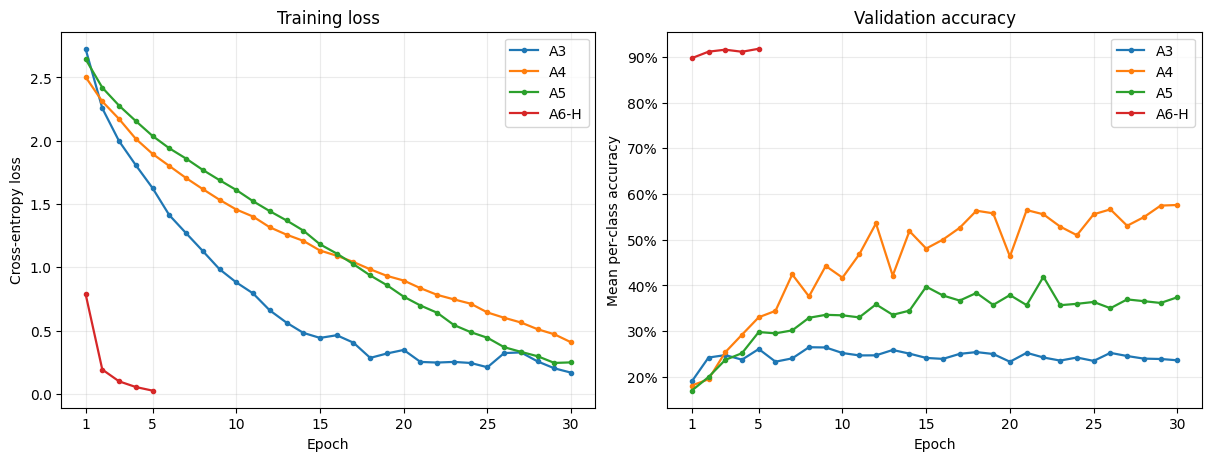

Saved: /content/drive/MyDrive/p1/results/learning_curves.png


In [18]:
# TODO Table 1 (e.g. a pandas DataFrame from TABLE1, saved to RESULTS_DIR), and the training-loss and
# validation-accuracy curves of A3, A4, A5 and A6-H. Copy your milestone predictions next to the results in your report.
# Functions: sum(p.numel() for p in model.parameters()); time.time(); pd.DataFrame(rows).to_csv(path); plt.plot
from matplotlib.ticker import PercentFormatter
import pandas as pd

results_dir = Path(RESULTS_DIR)
results_dir.mkdir(parents=True, exist_ok=True)
ckpt_dir = Path(CKPT_DIR)

my_classes = ["bicycle", "bottle", "chair", "car", "cat"]

class_ids = {
    "bicycle": 1,
    "bottle": 4,
    "chair": 8,
    "car": 6,
    "cat": 7,
}



# -------------------- Table 1 --------------------

model_order = [
    "A1", "A2-hsv", "A2-hog", "A2-gabor", "A2-concat",
    "A3", "A4", "A5", "A6-H", "A6-L",
]

table = pd.DataFrame(TABLE1).set_index("model", verify_integrity=True)

missing = [name for name in model_order if name not in table.index]
if missing:
    raise ValueError(
        f"Missing TABLE1 rows: {missing}. "
        f"Available rows: {table.index.tolist()}"
    )

table = table.loc[model_order].copy()

table["mean_class_test_acc_pct"] = 100 * table["mean_per_class_test_acc"]

for name, class_id in class_ids.items():
    table[f"{name}_test_acc_pct"] = [
        100 * float(per_class[class_id])
        for per_class in table["per_class_test_acc"]
    ]

columns = [
    "mean_class_test_acc_pct",
    *[f"{name}_test_acc_pct" for name in my_classes],
    "input_size",
    "feature_dimension",
    "parameters",
    "training_data",
    "training_time_seconds",
    "hardware",
]

table1_df = table[columns].reset_index()
table1_df["feature_dimension"] = table1_df["feature_dimension"].astype("Int64")
table1_df["parameters"] = table1_df["parameters"].astype("Int64")

table_path = results_dir / "table1.csv"
table1_df.to_csv(table_path, index=False, float_format="%.4f")

display(table1_df.round(2))
print(f"Saved: {table_path}")


# -------------------- Learning curves --------------------

history_files = {
    "A3":   ("a3_history.npz", 30),
    "A4":   ("a4_history.npz", 30),
    "A5":   ("a5_history.npz", 30),
    "A6-H": ("a6_h_history.npz", 5),
}

fig, (ax_loss, ax_acc) = plt.subplots(
    1, 2, figsize=(12, 4.5), constrained_layout=True
)

for model_name, (filename, expected_epochs) in history_files.items():
    with np.load(ckpt_dir / filename) as history:
        epochs = history["epoch"]
        loss = history["train_loss"]
        val_acc = history["val_mean_per_class_acc"]

    if not (
        len(epochs) == len(loss) == len(val_acc) == expected_epochs
    ):
        raise ValueError(f"{filename} should contain {expected_epochs} epochs.")

    line, = ax_loss.plot(
        epochs, loss, marker="o", markersize=3, linewidth=1.6,
        label=model_name,
    )
    ax_acc.plot(
        epochs, val_acc, color=line.get_color(),
        marker="o", markersize=3, linewidth=1.6, label=model_name,
    )

ax_loss.set(title="Training loss", ylabel="Cross-entropy loss")
ax_acc.set(
    title="Validation accuracy",
    ylabel="Mean per-class accuracy",
)
ax_acc.yaxis.set_major_formatter(PercentFormatter(xmax=1))

for ax in (ax_loss, ax_acc):
    ax.set_xlabel("Epoch")
    ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
    ax.grid(alpha=0.25)
    ax.legend()

figure_path = results_dir / "learning_curves.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {figure_path}")